# 05 – Đánh giá hiệu quả hệ hỗ trợ ra quyết định (DSS)

Công việc 6.2–6.3: hiệu quả cảnh báo trên hành vi thực tế, độ phủ luật, độ nhạy ngưỡng, case study.

> **Quyền riêng tư:** `customer_id` được dựng từ số điện thoại khách hàng. Notebook chỉ hiển thị số liệu tổng hợp hoặc mã đã che (`KH_0908***444`). Không in trực tiếp cột `customer_id` / `bill_phone_number` / `bill_full_name`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # bảng màu đã kiểm định CVD
from backend.ml import feature_engineering as fe
from backend.app.core.customer_store import mask_customer_id  # che số điện thoại khi hiển thị

## 1. Bảng luật DSS

In [2]:
from backend.app.core.dss_engine import describe_rules
pd.DataFrame(describe_rules()).set_index("rule_id")

,level,segments,churn_interval,warning,recommendation
rule_id,,,,,
R01_VIP_CRITICAL,CRITICAL,VIP,"(70%, 100%]",Khách hàng VIP có nguy cơ rời bỏ rất cao,"Chuyên viên VIP liên hệ trong 24h, tặng vouche..."
R02_HIGH_CHURN,HIGH,Mọi phân khúc trừ VIP,"(70%, 100%]",Nguy cơ rời bỏ cao,Tự động gửi Voucher giảm giá 15% và liên hệ CSKH
R03_AT_RISK_MEDIUM_CHURN,HIGH,Rủi ro,"[40%, 70%]",Khách hàng nhóm Rủi ro đang có dấu hiệu rời bỏ,Kích hoạt chiến dịch win-back: mã giảm giá 15%...
R04_AT_RISK_FLOOR,MEDIUM,Rủi ro,"[0%, 40%)",Khách hàng nhóm Rủi ro (giá trị/tần suất thấp)...,Gửi khảo sát trải nghiệm dịch vụ & mã giảm giá...
R05_VIP_DECLINING,MEDIUM,VIP,"[20%, 70%]",Khách hàng VIP đang giảm tần suất mua sắm,Gửi quà tặng cá nhân hóa & gán Chuyên viên hỗ ...
R06_POTENTIAL_DECLINING,MEDIUM,Tiềm năng,"[40%, 70%]",Khách hàng tiềm năng có dấu hiệu sụt giảm tươn...,Gửi email nhắc nhở giỏ hàng kèm ưu đãi freeship
R07_NEEDS_ATTENTION,MEDIUM,Cần chăm sóc,"[0%, 70%]",Cần kích hoạt lại nhu cầu mua sắm,Thực hiện khảo sát trải nghiệm dịch vụ & gửi m...
R08_UNKNOWN_MEDIUM_CHURN,MEDIUM,Không xác định,"[40%, 70%]",Nguy cơ rời bỏ trung bình (chưa xác định phân ...,Chạy phân cụm RFM để xác định phân khúc và the...
R09_VIP_LOYAL,LOW,VIP,"[0%, 20%)",NaN,Mời tham gia chương trình tri ân đặc quyền


## 2. Đánh giá trên hành vi thực tế (tập kiểm tra out-of-time)
`evaluate_dss.evaluate()` là cùng hàm sinh `dss_evaluation.json` cho API và báo cáo.

In [3]:
from backend.ml.evaluate_dss import SCORED_PATH, evaluate
scored = pd.read_csv(SCORED_PATH, dtype={"customer_id": str})
ev = evaluate(scored)
print(ev["data"])
groups = {"Cảnh báo khách tiềm năng": ev["opportunity_alerts"]["alerted"], "Không thuộc nhóm tiềm năng": ev["opportunity_alerts"]["not_alerted"],
          "Cảnh báo rủi ro (CRITICAL/HIGH)": ev["risk_alerts"]["alerted"], "Không cảnh báo rủi ro": ev["risk_alerts"]["not_alerted"]}
pd.DataFrame(groups).T[["customers", "actual_churn_rate", "actual_repurchase_rate", "repurchase_lift"]]

{'source': 'Tập kiểm tra out-of-time (scored_customers.csv), nhãn = hành vi thực tế trong cửa sổ kết quả', 'customers': 2724, 'base_actual_churn_rate': 0.9622, 'base_actual_repurchase_rate': 0.0378}


,customers,actual_churn_rate,actual_repurchase_rate,repurchase_lift
Cảnh báo khách tiềm năng,76.0,0.8816,0.1184,3.13
Không thuộc nhóm tiềm năng,2648.0,0.9645,0.0355,0.94
Cảnh báo rủi ro (CRITICAL/HIGH),662.0,0.9728,0.0272,0.72
Không cảnh báo rủi ro,2062.0,0.9588,0.0412,1.09


In [4]:
pd.DataFrame(ev["by_alert_level"]).T[["customers", "actual_churn_rate", "actual_repurchase_rate", "repurchase_lift", "mean_predicted_churn"]]

,customers,actual_churn_rate,actual_repurchase_rate,repurchase_lift,mean_predicted_churn
CRITICAL,2.0,1.0000,0.0000,0.00,0.7228
HIGH,660.0,0.9727,0.0273,0.72,0.6494
MEDIUM,2019.0,0.9599,0.0401,1.06,0.5198
LOW,43.0,0.9070,0.0930,2.46,0.3451


In [5]:
pd.DataFrame(ev["rule_coverage"]).set_index("rule_id")[["level", "customers", "actual_repurchase_rate", "repurchase_lift"]]

,level,customers,actual_repurchase_rate,repurchase_lift
rule_id,,,,
R01_VIP_CRITICAL,CRITICAL,2,0.0000,0.00
R02_HIGH_CHURN,HIGH,280,0.0214,0.57
R03_AT_RISK_MEDIUM_CHURN,HIGH,380,0.0316,0.84
R04_AT_RISK_FLOOR,MEDIUM,562,0.0463,1.22
R05_VIP_DECLINING,MEDIUM,100,0.0700,1.85
R06_POTENTIAL_DECLINING,MEDIUM,1002,0.0399,1.06
R07_NEEDS_ATTENTION,MEDIUM,355,0.0225,0.60
R08_UNKNOWN_MEDIUM_CHURN,MEDIUM,0,NaN,NaN
R09_VIP_LOYAL,LOW,0,NaN,NaN


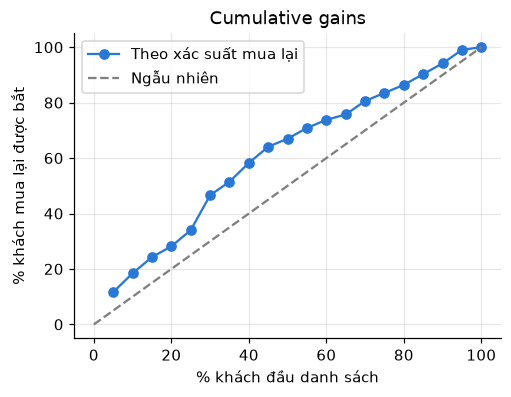

In [6]:
g = pd.DataFrame(ev["repurchase_ranking"]["cumulative_gains"])
ax = (g.set_index(g["population_share"] * 100)["captured_share"] * 100).plot(marker="o", color=C[0], figsize=(5, 3.6), label="Theo xác suất mua lại")
ax.plot([0, 100], [0, 100], "--", color="gray", label="Ngẫu nhiên"); ax.set_xlabel("% khách đầu danh sách"); ax.set_ylabel("% khách mua lại được bắt"); ax.legend()
ax.set_title("Cumulative gains");

## 3. Độ nhạy của ngưỡng khách tiềm năng
Ngưỡng 60% (= 100% − ngưỡng rủi ro trung bình 40% của DSS). Bảng dưới cho thấy đánh đổi giữa quy mô danh sách và tỷ lệ mua lại thực tế.

In [7]:
s = scored.assign(rep=1 - scored["churn_prob"], bought=(scored["actual_churn"] == 0).astype(int))
base = s["bought"].mean(); rows = []
for t in [0.5, 0.55, 0.6, 0.65, 0.7]:
    grp = s[s["rfm_segment"].isin(["VIP", "Tiềm năng"]) & (s["rep"] >= t)]
    rows.append({"ngưỡng mua lại": t, "số khách": len(grp), "mua lại thực tế": grp["bought"].mean() if len(grp) else np.nan,
                 "lift": grp["bought"].mean() / base if len(grp) else np.nan})
pd.DataFrame(rows).set_index("ngưỡng mua lại").round(3)

,số khách,mua lại thực tế,lift
ngưỡng mua lại,,,
0.50,253,0.079,2.091
0.55,139,0.108,2.854
0.60,76,0.118,3.132
0.65,42,0.167,4.408
0.70,15,0.267,7.052


## 4. Case study (mã đã che)

In [8]:
pd.DataFrame(ev["case_studies"]).set_index("title").T

title,VIP có nguy cơ rời bỏ cao,Khách tiềm năng có xu hướng mua lại,Khách chưa có đơn thành công (phân khúc Rủi ro)
display_id,KH_0853***408,KH_0987***935,KH_0967***230
segment,VIP,VIP,Rủi ro
recency_days,8.3,5.5,48.3
completed_orders,2,2,0
total_orders,2,2,1
monetary,340000.0,1300000.0,0.0
channel,TikTok Shop,Facebook Fanpage,Facebook Fanpage
region,Miền Nam,Miền Nam,Miền Bắc
churn_prob_pct,72.82,20.67,84.28
repurchase_prob_pct,27.18,79.33,15.72
